In [1]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader

import deep_models.config as c                                       
from deep_models.data import S00MILDataset, load_folds, make_splits 
from deep_models.vae import SparseConvVAE, plot_sparse_latent_usage
from deep_models.vae_train import encode_bags_sparse, init_model

from evaluation import (embed_raw_bags, extract_raw_from_loader, flatten_offdiag_bags, pca_bags,
                            plot_embedding_votes, run_nn_probes, select_dims, set_device)

In [2]:
device = c.device       
set_device(device)      
split_k = 7
LATENT_DIM = 64
COND_DIM = 2   # S00MILDataset condition: [age, female]
ALPHA = 0.1   # prior sparsity used when training the sparse VAE

In [3]:
developamental_folds = load_folds(c.dev_path)
_, train_idx, val_idx, test_idx = next(split for split in make_splits(developamental_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")

train=1085  val=132  test=136


In [4]:
trainset = S00MILDataset(train_idx, max_instances=150, train=True, return_cond=True)
valset = S00MILDataset(val_idx, max_instances=150, train=False, return_cond=True)
testset = S00MILDataset(test_idx, max_instances=150, train=False, return_cond=True)


loader_kw = dict(batch_size=10, num_workers=4, pin_memory=True) 
trainloader = DataLoader(trainset, shuffle=True, **loader_kw)  
valloader = DataLoader(valset, shuffle=False, **loader_kw) 
testloader = DataLoader(testset, shuffle=False, **loader_kw)

In [5]:
raw_tr, y_train, cond_tr = extract_raw_from_loader(trainloader)
raw_va, y_val, cond_va = extract_raw_from_loader(valloader)
raw_te, y_test, cond_te = extract_raw_from_loader(testloader)

raw_splits = {"train": raw_tr, "val": raw_va, "test": raw_te}
cond_splits = {"train": cond_tr, "val": cond_va, "test": cond_te}   # (exams, COND_DIM): [age, female]

### 1. Baseline: Flattened off-diagonal raw inputs (5 * 17 * 16 = 1360 dims)


In [6]:
bags = {"raw_offdiag": {s: flatten_offdiag_bags(raw_splits[s]) for s in ("train", "val", "test")}}

### 2. Baseline: PCA on flattened off-diagonal raw inputs (64 dims, matching VAE latent_dim)

In [7]:
bags["pca"] = pca_bags(bags["raw_offdiag"], n_components=LATENT_DIM, seed=0)

### 2b. Control: the condition alone (age, sex), no EEG
What the probes reach from the same condition the VAE was given. The codes only add something if they beat this.

In [8]:
bags["cond_only"] = {s: [np.repeat(cond[None], len(raw), axis=0) for cond, raw in zip(cond_splits[s], raw_splits[s])]
                     for s in ("train", "val", "test")}

### 3. Random conditional SparseConvVAE (initialized with init_model, NO training)

In [9]:
torch.manual_seed(0)
vae_rand = SparseConvVAE(latent=LATENT_DIM, alpha=ALPHA, cond_dim=COND_DIM).to(device)
init_model(vae_rand, trainloader)  
vae_rand.eval()

bags["sparse_random_z"] = {s: embed_raw_bags(vae_rand, raw_splits[s], cond_bags=cond_splits[s]) for s in ("train", "val", "test")}

### 4. Trained conditional SparseConvVAE

In [10]:
torch.manual_seed(0)
vae_trained = SparseConvVAE(latent=64, alpha=ALPHA, cond_dim=COND_DIM).to(device)  
state_dict = torch.load(f"best_scvae_split{split_k}.pt" , map_location=device, weights_only=True)
vae_trained.load_state_dict(state_dict)
vae_trained.eval()

bags["sparse_trained_z"] = {s: embed_raw_bags(vae_trained, raw_splits[s], cond_bags=cond_splits[s]) for s in ("train", "val", "test")}

#### Sparse code usage (validation)

used units: 31/64   mean L0 per window: 30.8


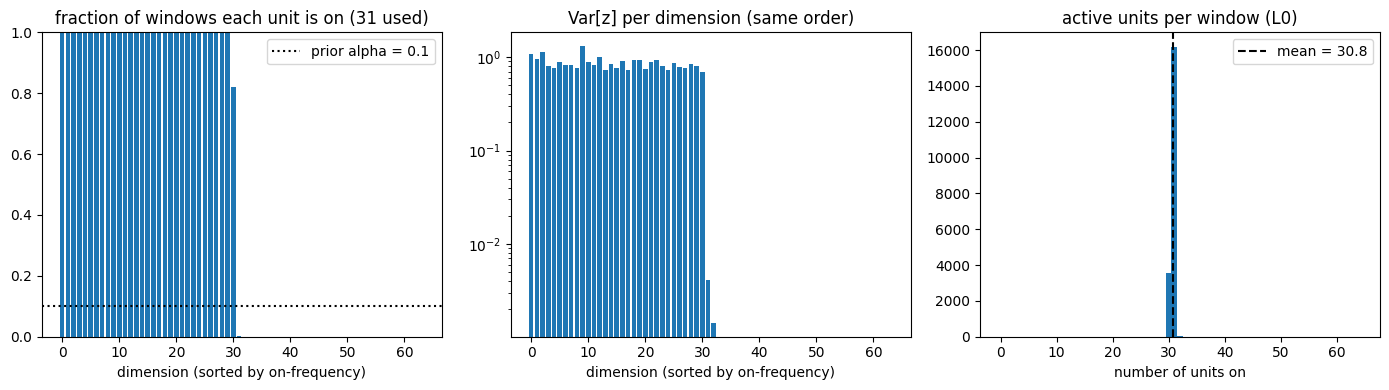

In [11]:
z_va, gamma_va, _ = encode_bags_sparse(vae_trained, valloader, device)
fig, order, n_used = plot_sparse_latent_usage(z_va, gamma_va, alpha=ALPHA)
plt.show()

### 5. Trained sparse VAE - used dimensions (on in more than 1% of train windows)

In [12]:
z_train = np.concatenate(bags["sparse_trained_z"]["train"])  
on_freq = (z_train != 0).mean(axis=0)                          
mask = on_freq > 0.01
print(f"Trained sparse VAE used units: {mask.sum()} / {LATENT_DIM}   (mean units on per window: {(z_train != 0).sum(1).mean():.1f})")
bags["sparse_trained_z_active"] = select_dims(bags["sparse_trained_z"], mask)

Trained sparse VAE used units: 31 / 64   (mean units on per window: 30.8)


In [13]:
representations = ["raw_offdiag", "pca", "cond_only", "sparse_random_z", "sparse_trained_z", "sparse_trained_z_active"]

In [ ]:
rows, artifacts = run_nn_probes(bags=bags,
                                representations=representations,
                                y_train=y_train,
                                y_val=y_val,
                                y_test=y_test,
                                return_artifacts=True,
                                abmil_variants={"ABMIL_linear": None, "ABMIL_h64": 64})
df = pd.DataFrame(rows)

[raw_offdiag] LinearBagProbe  val AUC = 0.698  epoch = 73  test AUC = 0.772
[raw_offdiag] LinearInstanceProbeBagLabels_soft  val AUC = 0.696  epoch = 6  test AUC = 0.746
[raw_offdiag] LinearInstanceProbeBagLabels_vote  val AUC = 0.701  epoch = 6  test AUC = 0.748
[raw_offdiag] ABMIL_linear  val AUC = 0.666  epoch = 12  test AUC = 0.660
[raw_offdiag] ABMIL_h64  val AUC = 0.686  epoch = 8  test AUC = 0.739
[pca] LinearBagProbe  val AUC = 0.674  epoch = 6  test AUC = 0.726
[pca] LinearInstanceProbeBagLabels_soft  val AUC = 0.723  epoch = 42  test AUC = 0.604
[pca] LinearInstanceProbeBagLabels_vote  val AUC = 0.743  epoch = 42  test AUC = 0.600
[pca] ABMIL_linear  val AUC = 0.722  epoch = 6  test AUC = 0.733
[pca] ABMIL_h64  val AUC = 0.723  epoch = 12  test AUC = 0.727
[cond_only] LinearBagProbe  val AUC = 0.537  epoch = 10  test AUC = 0.479


## Visualization in 2-dims

In [ ]:
embeddings_2d = {rep: TSNE(n_components=2, init="pca", learning_rate="auto", random_state=0).fit_transform(artifacts[rep]["X_val"]) for rep in representations}

In [ ]:
val_sizes = np.array([len(b) for b in bags["sparse_trained_z"]["val"]])
exam_ids = np.repeat(np.arange(len(val_sizes)), val_sizes)
window_labels = np.repeat(y_val, val_sizes)

In [ ]:
fig, axes = plot_embedding_votes(embeddings=embeddings_2d,
                                 artifacts=artifacts,
                                 exam_ids=exam_ids,
                                 window_labels=window_labels,
                                 rep_of=representations,
                                 mode="prob")
plt.show()

In [ ]:
fig, axes = plot_embedding_votes(embeddings=embeddings_2d,
                                 artifacts=artifacts,
                                 exam_ids=exam_ids,
                                 window_labels=window_labels,
                                 rep_of=representations,
                                 mode="vote")
plt.show()